# 01 · Data quality, sessions and the overall funnel
Reads the tables built by `run_sql.py` (sql/01–04). Checks data quality, the sessionization
sensitivity, and how often purchases skip a funnel step.

In [1]:
import json, os
from pathlib import Path
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DB = os.environ.get("FUNNEL_DB", ROOT / "data/processed/funnel.duckdb")
FIG = ROOT / "outputs/figures"; FIG.mkdir(parents=True, exist_ok=True)
RESULTS = ROOT / "outputs/results.json"
con = duckdb.connect(str(DB), read_only=True)
results = json.loads(RESULTS.read_text()) if RESULTS.exists() else {}
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
file_stats = con.sql("SELECT * FROM file_stats").df()
sample = con.sql("SELECT count(*) AS events, count(DISTINCT user_id) AS users FROM events").df()
print(file_stats, sample, sep="\n")
results["file_events"] = int(file_stats.n_events[0]); results["file_users"] = int(file_stats.n_users[0])
results["sample_events"] = int(sample.events[0]); results["sample_users"] = int(sample.users[0])

   n_events  n_users
0  42448764  3022290
    events   users
0  4231663  302351


## Data quality log

In [3]:
dq = con.sql("SELECT * FROM dq_log ORDER BY step").df()
dq.to_csv(ROOT / "outputs/dq_log.csv", index=False)
results["dq_log"] = dq.to_dict("records")
dq

,step,check_name,n_rows,action
0,1,Sampled rows,4241074,kept
1,2,"Exact duplicate events (same time, type, produ...",2963,dropped
2,3,Price <= 0 or missing,6448,dropped
3,4,Unknown event_type,0,dropped
4,5,Missing category_code,1347268,"kept, labeled ""unknown"""
5,6,Missing brand,609025,kept
6,7,Missing user_session,0,kept (sessions are rebuilt in 02)
7,8,Events outside 2019-10-01..2019-10-31,0,dropped
8,9,Clean events after all checks,4231663,analysis table


In [4]:
types = con.sql("SELECT event_type, count(*) AS n FROM events GROUP BY 1 ORDER BY n DESC").df()
results["event_types"] = dict(zip(types.event_type, types.n.astype(int)))
types

,event_type,n
0,view,4065932
1,cart,90230
2,purchase,75501


## Sessionization sensitivity (10 / 30 / 60 minutes)

In [5]:
sc = con.sql("SELECT * FROM session_counts").df()
results["sessions_by_gap"] = dict(zip(sc.gap_minutes.astype(str), sc.n_sessions.astype(int)))
sens = con.sql("SELECT * FROM sensitivity WHERE carted >= 100").df()
wide = sens.pivot(index="category", columns="gap_minutes", values="cart_to_purchase")
rho_10 = spearmanr(wide[10], wide[30]).statistic
rho_60 = spearmanr(wide[60], wide[30]).statistic
overall = con.sql("""SELECT gap_minutes, sum(purchased) / sum(carted) AS rate FROM sensitivity
                     GROUP BY 1 ORDER BY 1""").df()
results["sensitivity"] = {"spearman_10_vs_30": round(rho_10, 3), "spearman_60_vs_30": round(rho_60, 3),
                          "cart_to_purchase_by_gap": dict(zip(overall.gap_minutes.astype(str), overall.rate.round(4)))}
print(sc, overall, f"Spearman rank correlation of category rates: 10 vs 30 = {rho_10:.3f}, 60 vs 30 = {rho_60:.3f}", sep="\n")
wide.round(3)

   gap_minutes  n_sessions
0           10      840984
1           30      779252
2           60      752293
   gap_minutes      rate
0           10  0.496416
1           30  0.504922
2           60  0.507824
Spearman rank correlation of category rates: 10 vs 30 = 1.000, 60 vs 30 = 1.000


gap_minutes,10,30,60
category,,,
appliances,0.433,0.443,0.447
auto,0.452,0.459,0.462
computers,0.442,0.447,0.451
construction,0.424,0.433,0.432
electronics,0.529,0.537,0.540
furniture,0.359,0.377,0.377
kids,0.294,0.301,0.307
unknown,0.388,0.395,0.398


## Session funnel and skipped steps
Strict order: a session reaches Cart only with a cart after a view, and Purchase only with a
purchase after such a cart. Purchases with no earlier cart in the same session are counted separately.

In [6]:
fs = con.sql("""SELECT count(*) AS sessions, sum(viewed::INT) AS viewed, sum(carted::INT) AS carted,
                       sum(purchased::INT) AS purchased, sum(any_purchase::INT) AS any_purchase
                FROM funnel_session""").df().iloc[0]
skip = con.execute("""SELECT sum(purchase_skipped_step::INT) / sum(any_purchase) AS share FROM funnel_sp""").fetchone()[0]
results["session_funnel"] = {k: int(v) for k, v in fs.items()}
results["purchase_skip_share"] = round(skip, 4)
print(fs, f"Share of purchased session-products with no earlier cart in the session: {skip:.1%}", sep="\n")

sessions        779252.0
viewed          779076.0
carted           52134.0
purchased        27206.0
any_purchase     59067.0
Name: 0, dtype: float64
Share of purchased session-products with no earlier cart in the session: 55.9%


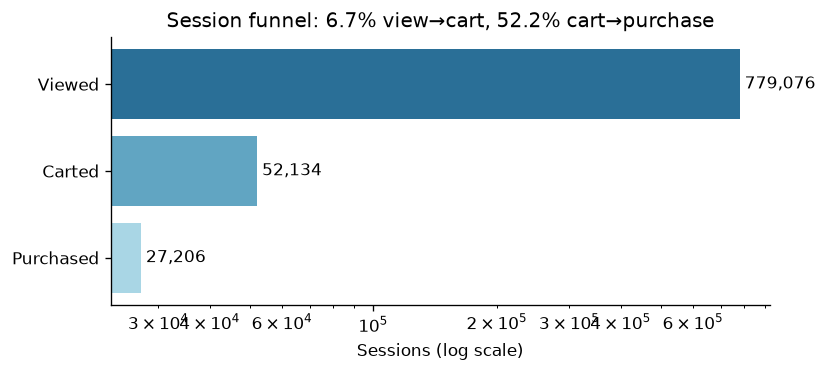

In [7]:
steps = ["Viewed", "Carted", "Purchased"]
vals = [fs.viewed, fs.carted, fs.purchased]
fig, ax = plt.subplots(figsize=(7, 3.2))
bars = ax.barh(steps[::-1], vals[::-1], color=["#2a6f97", "#61a5c2", "#a9d6e5"][::-1])
for b, v in zip(bars, vals[::-1]):
    ax.text(b.get_width(), b.get_y() + b.get_height() / 2, f" {v:,.0f}", va="center")
ax.set_xscale("log"); ax.set_xlabel("Sessions (log scale)")
ax.set_title(f"Session funnel: {fs.carted / fs.viewed:.1%} view→cart, {fs.purchased / fs.carted:.1%} cart→purchase")
fig.tight_layout(); fig.savefig(FIG / "session_funnel.png"); plt.show()

## Sankey of session outcomes

In [8]:
import plotly.graph_objects as go
any_buy_no_cart = int(fs.any_purchase - fs.purchased)
labels = ["Viewed", "Carted", "Left without cart", "Purchased", "Abandoned cart"]
src = [0, 0, 1, 1]; tgt = [1, 2, 3, 4]
val = [fs.carted, fs.viewed - fs.carted, fs.purchased, fs.carted - fs.purchased]
sankey = go.Figure(go.Sankey(node=dict(label=labels, pad=20, color=["#2a6f97", "#61a5c2", "#cccccc", "#2d6a4f", "#e76f51"]),
                             link=dict(source=src, target=tgt, value=val)))
sankey.update_layout(title=f"Session outcomes (another {any_buy_no_cart:,} sessions bought without a logged cart)",
                     width=900, height=420)
sankey.write_html(FIG / "sankey.html", include_plotlyjs="cdn")
try:
    sankey.write_image(FIG / "sankey.png", scale=2)
except Exception as e:  # kaleido needs a local Chrome
    print("PNG export skipped:", e)

In [9]:
RESULTS.write_text(json.dumps(results, indent=2, default=float))

1852